# 🌧️ Rainfall Prediction with Random Forest

Predict whether it will rain on a given day from daily weather measurements (pressure, temperature, humidity, cloud cover, sunshine, wind).

**Author:** Reda Akram · Computer Science (AI), University of Technology – Baghdad

## 1. Setup

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score
sns.set_theme(style="whitegrid"); RANDOM_STATE = 42

## 2. Load and clean the data
The raw CSV has stray spaces in some column names (e.g. `'pressure '`, `'         winddirection'`), so we strip them first.

In [2]:
df = pd.read_csv("data/Rainfall.csv")
df.columns = df.columns.str.strip()
print(df.shape)
df.head()

(366, 12)


,day,pressure,maxtemp,temparature,mintemp,dewpoint,humidity,cloud,rainfall,sunshine,winddirection,windspeed
0,1,1025.9,19.9,18.3,16.8,13.1,72,49,yes,9.3,80.0,26.3
1,2,1022.0,21.7,18.9,17.2,15.6,81,83,yes,0.6,50.0,15.3
2,3,1019.7,20.3,19.3,18.0,18.4,95,91,yes,0.0,40.0,14.2
3,4,1018.9,22.3,20.6,19.1,18.8,90,88,yes,1.0,50.0,16.9
4,5,1015.9,21.3,20.7,20.2,19.9,95,81,yes,0.0,40.0,13.7


In [3]:
df.isnull().sum()

day              0
pressure         0
maxtemp          0
temparature      0
mintemp          0
dewpoint         0
humidity         0
cloud            0
rainfall         0
sunshine         0
winddirection    1
windspeed        1
dtype: int64

Only a couple of rows have missing values, so dropping them is safe.

The `day` column is just the day-of-month counter. It carries no physical information about the weather, so it is **removed from the features** (keeping it would let the model memorise row order instead of learning weather patterns).

In [4]:
df = df.dropna()
df["rainfall"] = df["rainfall"].map({"yes": 1, "no": 0})
X = df.drop(columns=["rainfall", "day"])
y = df["rainfall"]
print("Class balance:\n", y.value_counts(normalize=True).round(3))

Class balance:
 rainfall
1    0.679
0    0.321
Name: proportion, dtype: float64


## 3. Quick EDA

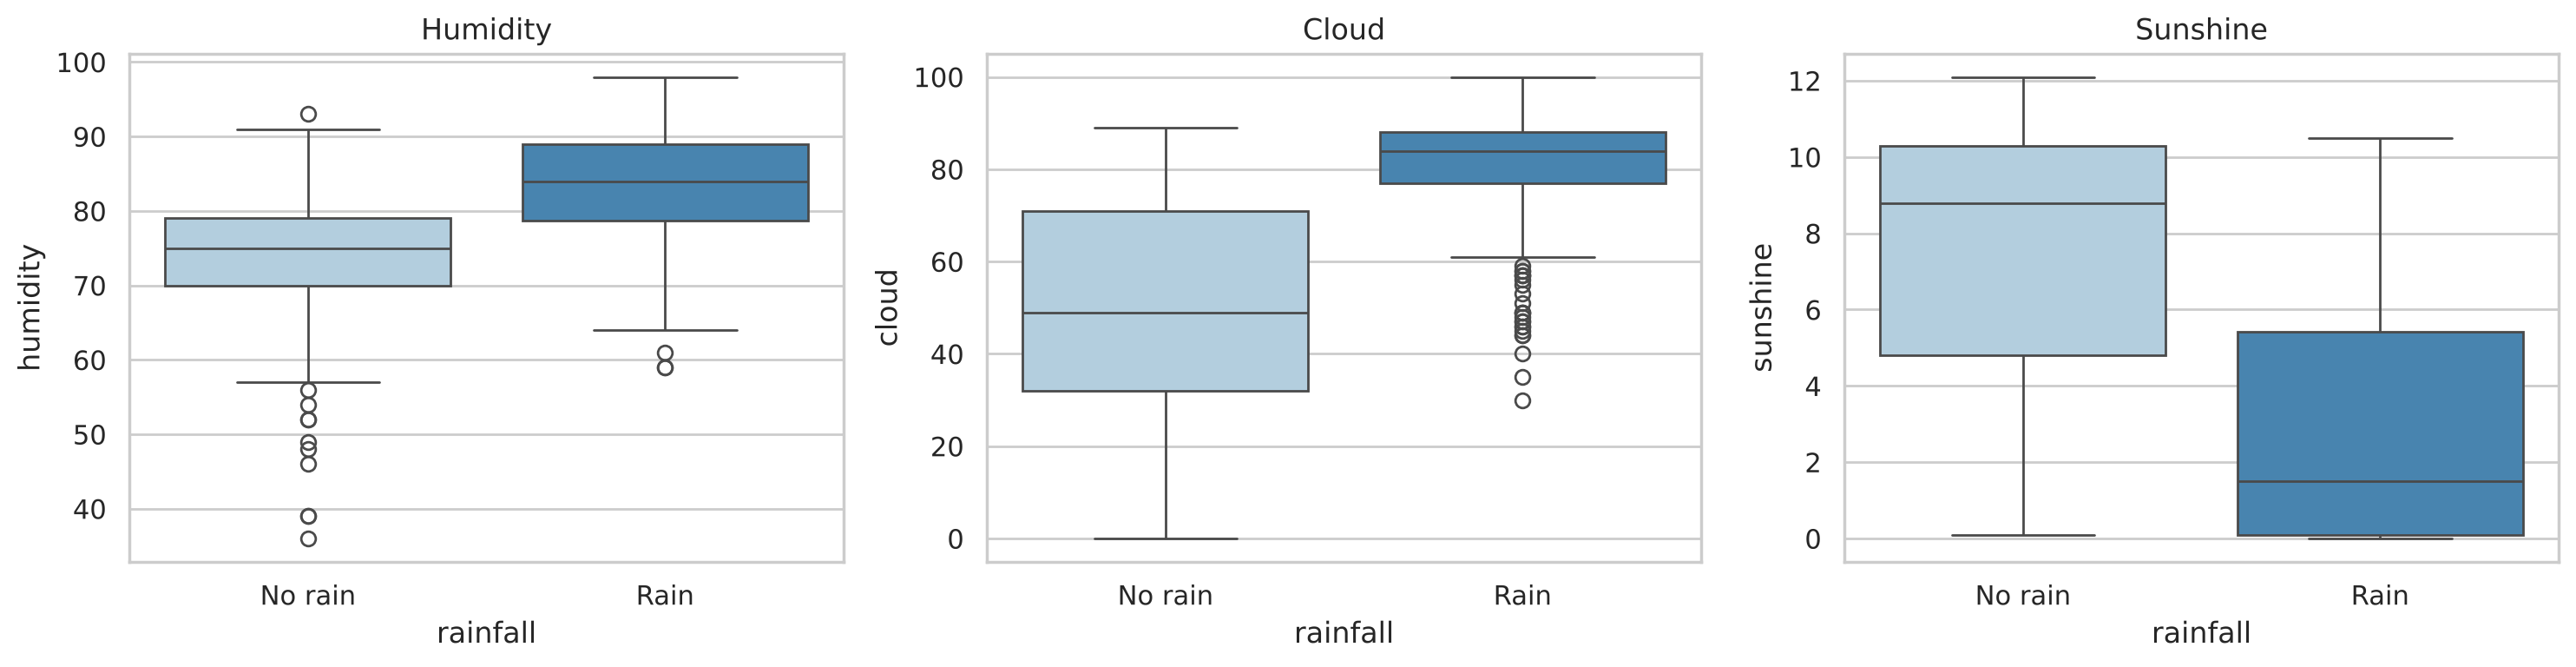

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["humidity", "cloud", "sunshine"]):
    sns.boxplot(data=df, x="rainfall", y=col, hue="rainfall", ax=ax, palette="Blues", legend=False)
    ax.set_xticks([0, 1], ["No rain", "Rain"]); ax.set_title(col.capitalize())
plt.tight_layout(); plt.savefig("images/eda_boxplots.png", dpi=120, bbox_inches="tight"); plt.show()

Rainy days clearly have **higher humidity and cloud cover** and **much less sunshine**, so these should be the strongest signals.

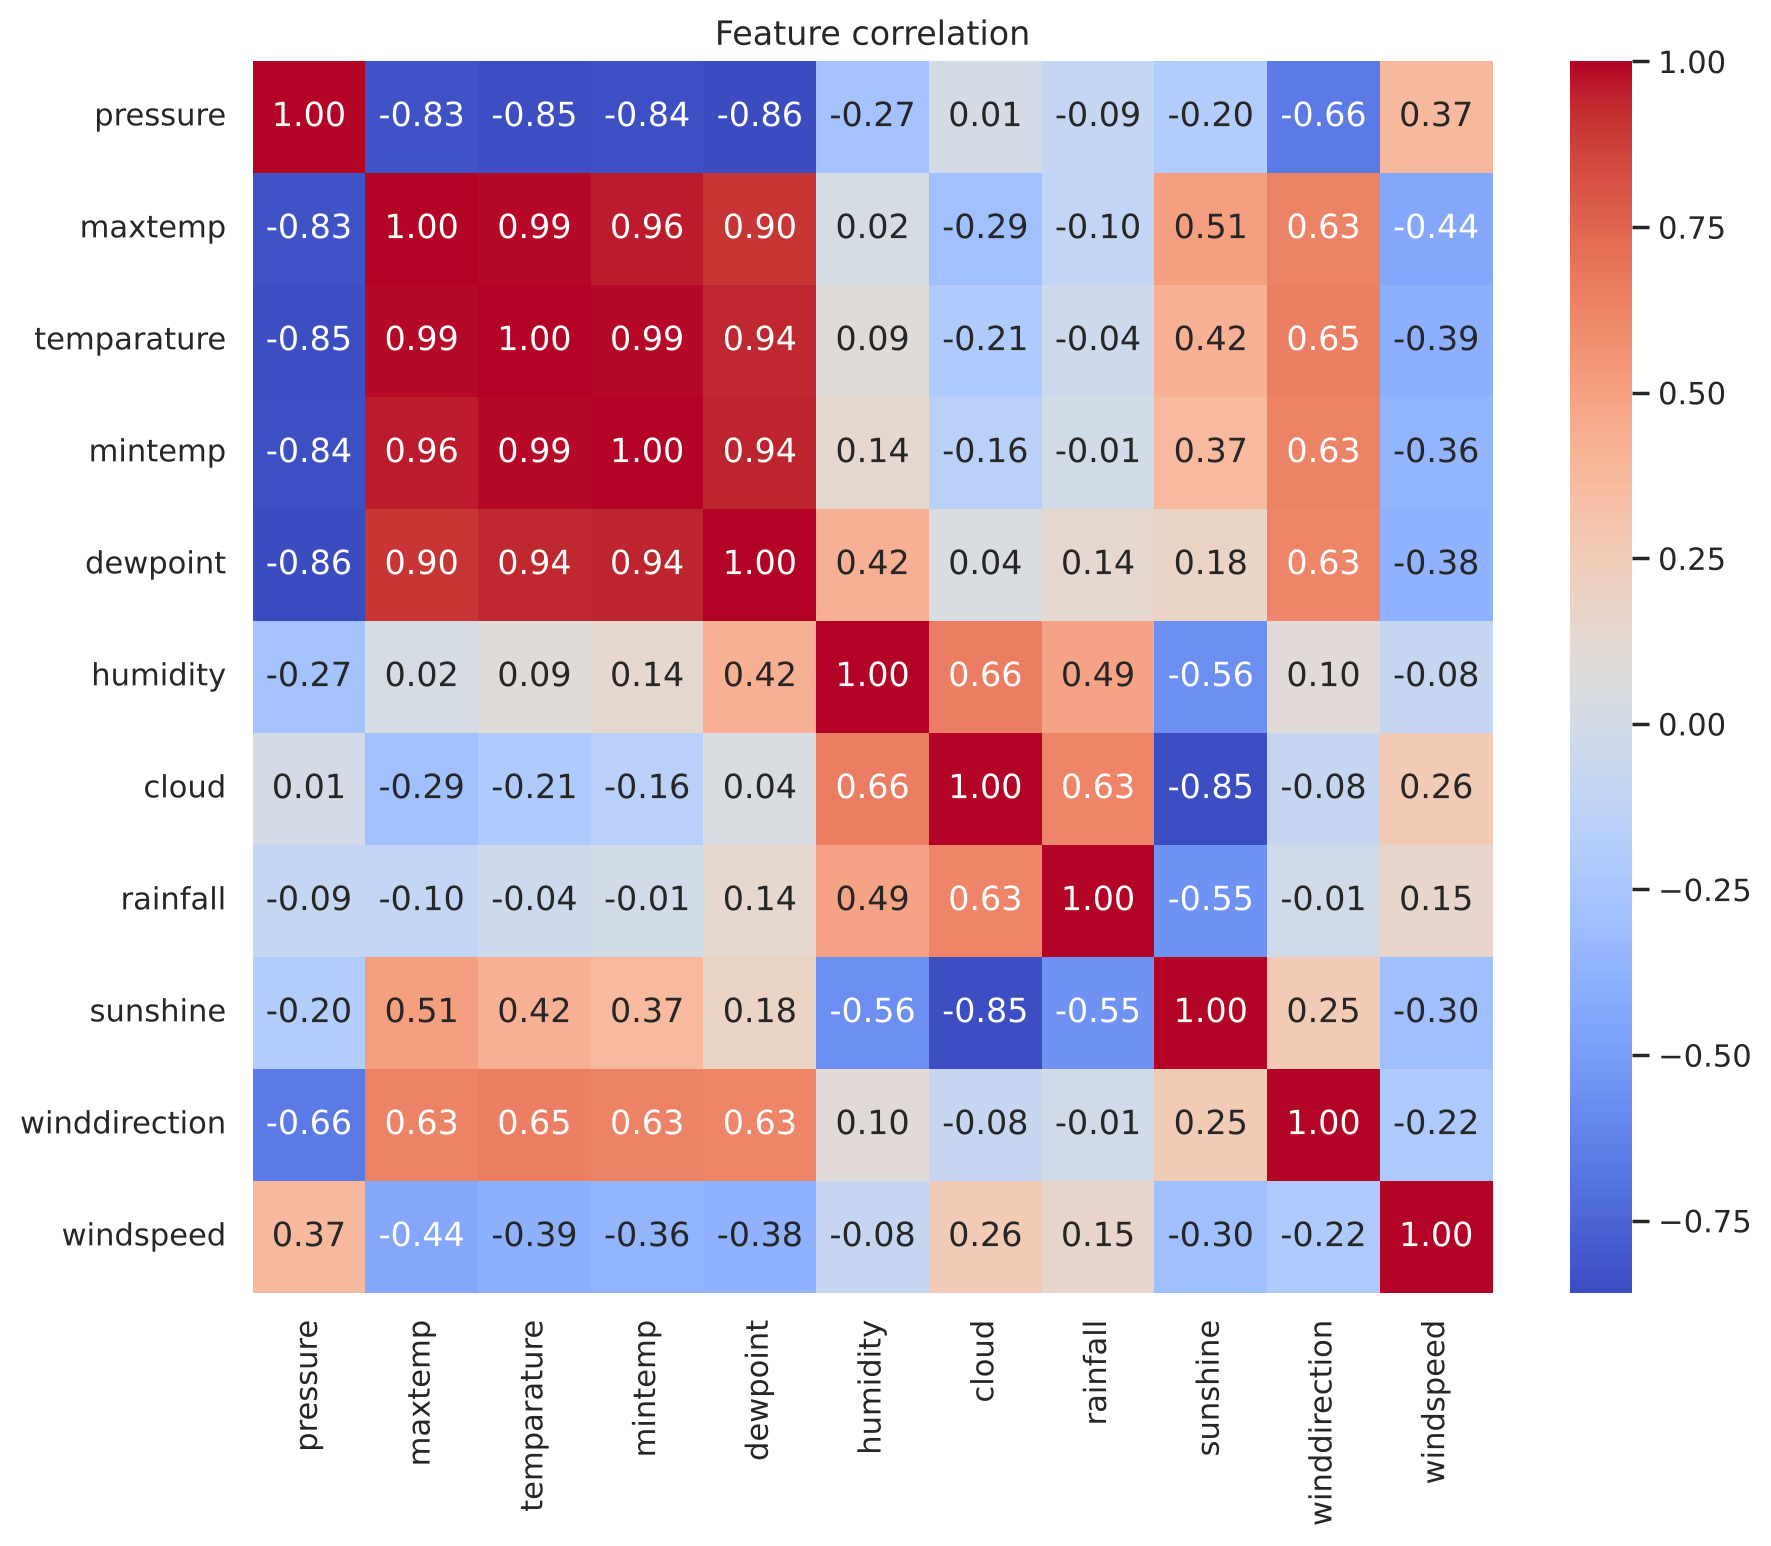

In [6]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.drop(columns="day").corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Feature correlation"); plt.savefig("images/correlation.png", dpi=120, bbox_inches="tight"); plt.show()

## 4. Model: Random Forest + GridSearchCV
`stratify=y` keeps the same rain / no-rain ratio in train and test, because the classes are imbalanced.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

pipe = Pipeline([("imputer", SimpleImputer(strategy="mean")),
                 ("model", RandomForestClassifier(random_state=RANDOM_STATE))])
param_grid = {
    "model__n_estimators": [100, 200, 300],
    "model__max_depth": [None, 5, 10, 20],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": [None, "sqrt", "log2"],
}
grid = GridSearchCV(pipe, param_grid, cv=5, scoring="f1", n_jobs=-1)
grid.fit(X_train, y_train)
print("Best params:", grid.best_params_)
print("Best CV F1 :", round(grid.best_score_, 3))

Best params: {'model__max_depth': 5, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 1, 'model__min_samples_split': 10, 'model__n_estimators': 100}
Best CV F1 : 0.869


## 5. Evaluation on the test set

In [8]:
y_pred = grid.predict(X_test)
print(classification_report(y_test, y_pred, target_names=["No rain", "Rain"]))

              precision    recall  f1-score   support

     No rain       0.79      0.65      0.71        23
        Rain       0.85      0.92      0.88        50

    accuracy                           0.84        73
   macro avg       0.82      0.79      0.80        73
weighted avg       0.83      0.84      0.83        73



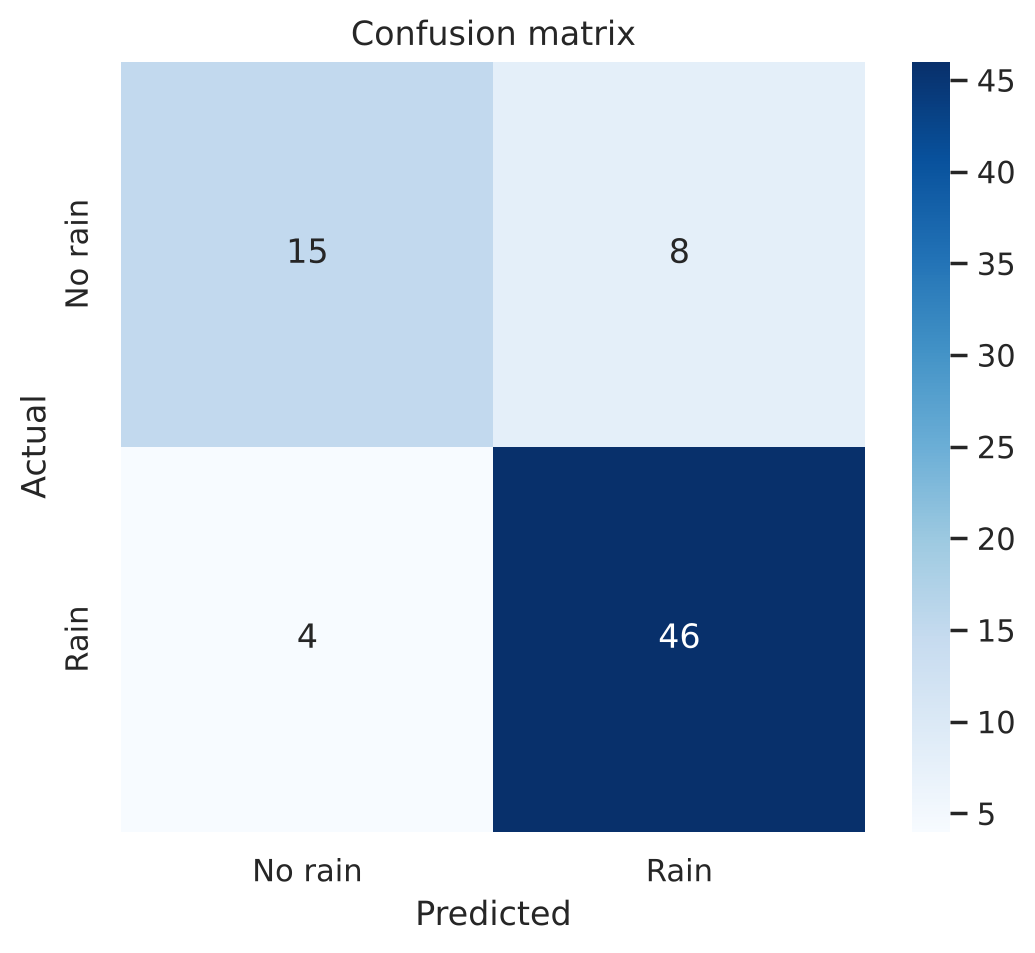

In [9]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["No rain", "Rain"], yticklabels=["No rain", "Rain"])
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Confusion matrix")
plt.savefig("images/confusion_matrix.png", dpi=120, bbox_inches="tight"); plt.show()

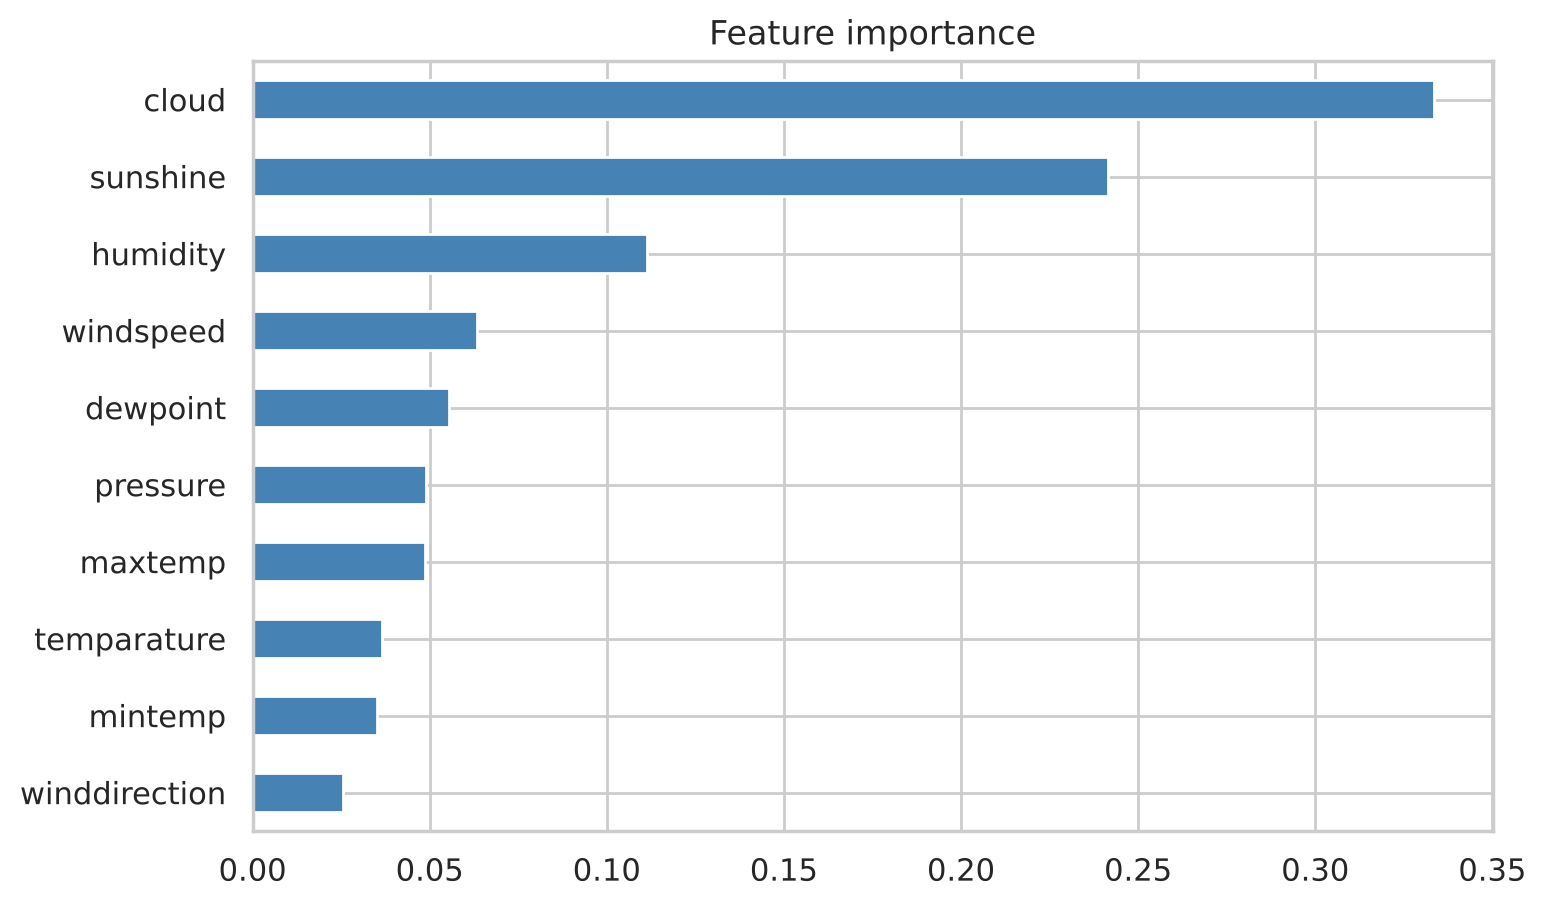

In [10]:
imp = pd.Series(grid.best_estimator_.named_steps["model"].feature_importances_, index=X.columns).sort_values()
imp.plot(kind="barh", figsize=(8, 5), color="steelblue"); plt.title("Feature importance")
plt.savefig("images/feature_importance.png", dpi=120, bbox_inches="tight"); plt.show()

In [11]:
results = {"accuracy": accuracy_score(y_test, y_pred), "f1_rain": f1_score(y_test, y_pred)}
results

{'accuracy': 0.8356164383561644, 'f1_rain': 0.8846153846153846}

## 6. Conclusion

* The model's **recall for rain is higher than its precision**: it rarely misses a rainy day, at the cost of some false alarms.
* For a weather app this is the right trade-off — telling someone to take an umbrella on a dry day is much cheaper than missing a rainy one.
* Cloud cover, sunshine and humidity carry most of the signal, which matches the EDA.

**Next steps:** add lag features (yesterday's weather), try gradient boosting, and tune the decision threshold for the desired recall.